# H01. 냉각기 상태에 따라 냉각 효율이 다른가

| 항목 | 내용 |
|---|---|
| 질문 | 냉각기가 나빠지면(100% → 20% → 3%) 냉각 효율 값이 달라질까? |
| 귀무가설 H0 | 냉각기 상태 3개 그룹의 냉각 효율(CE_mean) 분포는 같다 |
| 대립가설 H1 | 적어도 한 그룹의 분포가 다르다 |
| 검정 | Kruskal-Wallis → Dunn 사후검정(Holm), 효과 크기 ε² |
| 출처 (EDA) | F09 바이올린 플롯, F25 효과 크기 히트맵 |
| 데이터 | hyd_cycles.csv: CE_mean × cooler_pct |
| 왜 중요한가 | 냉각기 진단에 어떤 센서를 쓰면 되는지 근거 |

**진행 순서:** 1 EDA 시각화 → 2 기술통계 → 3 가정 확인 → 4 정상성 확인 → 5 가설검정(p-값) → 6 사후검정·효과 크기 → 7 블록 평균 재확인 → 8 최종 판정 → 9 해석과 결정

유의수준은 **α = 0.05**로 미리 정했습니다. 표본이 2,205개로 커서 작은 차이도 p < 0.05가 되므로, **결론은 효과 크기와 함께** 내립니다.

In [1]:
from common import *
cyc = load_cycles()
print(cyc.shape)

(2205, 75)


## 1. EDA 시각화

상태별 분포(바이올린)와 사이클 순서에 따른 값(시계열)을 함께 봅니다.

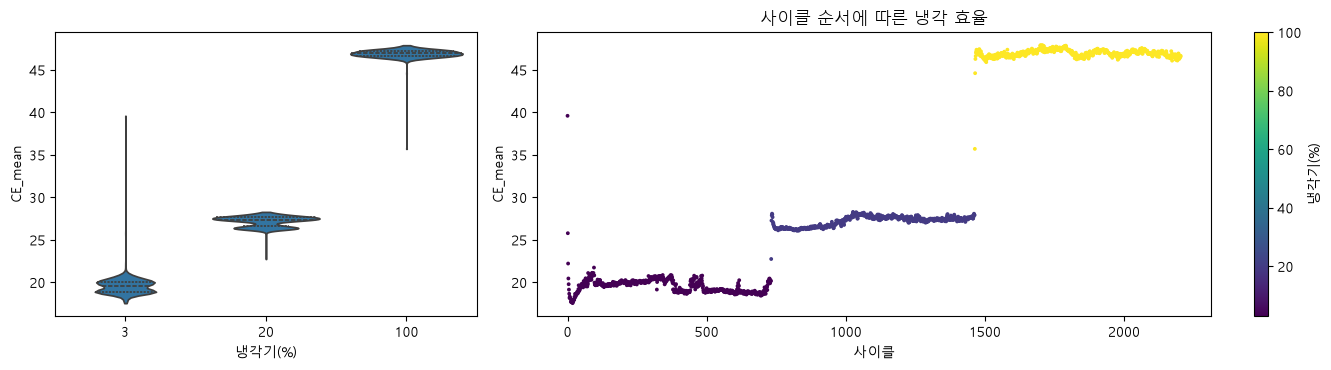

In [2]:
f, c = "CE_mean", "cooler_pct"
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), gridspec_kw={"width_ratios": [1, 2]})
sns.violinplot(data=cyc, x=c, y=f, ax=axes[0], inner="quartile", cut=0); axes[0].set_xlabel(COMP[c])
sc = axes[1].scatter(cyc["cycle"], cyc[f], c=cyc[c], s=3, cmap="viridis"); plt.colorbar(sc, ax=axes[1], label=COMP[c])
axes[1].set_xlabel("사이클"); axes[1].set_ylabel(f); axes[1].set_title("사이클 순서에 따른 냉각 효율")
plt.tight_layout(); plt.show()

**EDA로 본 것:** 세 상태의 분포가 거의 겹치지 않습니다. 시계열을 보면 냉각기 상태가 실험 중 **세 블록**(0~731, 732~1463, 1464~2204)으로 바뀌어서, 시간과 상태가 겹쳐 있습니다. 그래서 7단계 블록 평균 재확인이 필요합니다.

**참고:** 다른 센서들도 냉각기에 반응하는지 효과 크기로 훑어봅니다 (F25의 냉각기 열).

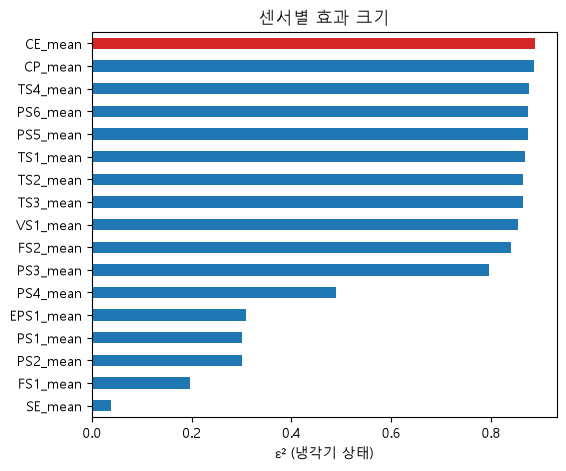

In [3]:
MEAN = [x for x in features(cyc) if x.endswith("_mean")]
e = pd.Series({m: kruskal_test(cyc[m], cyc[c])["eps2"] for m in MEAN}).sort_values()
e.plot.barh(figsize=(6, 5), color=["C3" if m == f else "C0" for m in e.index]); plt.xlabel("ε² (냉각기 상태)"); plt.title("센서별 효과 크기"); plt.show()

## 2. 기술통계

In [4]:
display(cyc.groupby(c)[f].describe().round(2))

,count,mean,std,min,25%,50%,75%,max
cooler_pct,,,,,,,,
3,732.0,19.57,1.05,17.56,18.91,19.63,20.08,39.60
20,732.0,27.20,0.60,22.75,26.60,27.38,27.64,28.29
100,741.0,46.93,0.56,35.71,46.67,46.94,47.23,47.90


## 3. 가정 확인 → 검정 방법 고르기

- **정규성:** 그룹마다 D'Agostino K² 검정과 Q-Q 플롯으로 봅니다. 표본이 크면 검정은 작은 벗어남에도 기각하므로 **Q-Q 플롯을 함께** 봅니다.
- **등분산:** Levene 검정(중앙값 기준)으로 봅니다.
- 정규성과 등분산이 성립하면 일원 ANOVA를 쓰고, 성립하지 않으면 **Kruskal-Wallis(비모수)**를 씁니다.

,그룹,n,왜도,K2,정규성_p,정규분포
0,3,732,9.67,1199.3,3.79e-261,아니오
1,20,732,-0.93,132.8,1.45e-29,아니오
2,100,741,-11.01,1296.7,2.69e-282,아니오


Levene W = 56.42, p = 1.28e-24 → 등분산: 아니오


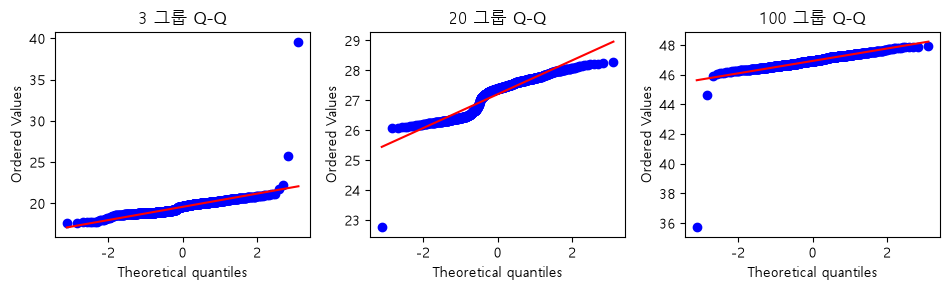

선택한 검정: Kruskal-Wallis (비모수)


In [5]:
tab, lev = assumption_table(cyc['CE_mean'], cyc['cooler_pct'])
display(tab.style.format({"왜도": "{:.2f}", "K2": "{:.1f}", "정규성_p": "{:.2e}"}))
print(f"Levene W = {lev['W']:.2f}, p = {lev['p']:.2e} → 등분산: {lev['등분산']}")
groups = sorted(cyc['cooler_pct'].unique())
fig, axes = plt.subplots(1, len(groups), figsize=(3.2 * len(groups), 3))
for ax, gv in zip(axes, groups):
    stats.probplot(cyc.loc[cyc['cooler_pct'] == gv, 'CE_mean'].dropna(), dist="norm", plot=ax); ax.set_title(f"{gv} 그룹 Q-Q")
plt.tight_layout(); plt.show()
use_nonparam = (tab["정규분포"] == "아니오").any() or lev["등분산"] == "아니오"
print("선택한 검정:", "Kruskal-Wallis (비모수)" if use_nonparam else "일원 ANOVA")

## 4. 정상성 확인

사이클 순서대로 본 이 특징이 **정상(평균·분산이 시간에 따라 일정)**인지 확인합니다. ADF(H0: 비정상)와 KPSS(H0: 정상)는 질문이 반대라서 함께 봅니다.

- 비정상이거나 자기상관이 크면 "관측값이 서로 독립"이라는 검정의 가정이 약해집니다. 그래서 7단계에서 **50사이클 블록 평균으로 다시 검정**합니다.
- KPSS p가 0.01이나 0.10으로 나오면 경계값입니다. 각각 "0.01 이하", "0.10 이상"으로 읽습니다.


,특징,계열,ADF_p,KPSS_p,판정
0,CE_mean,원값,0.8326,0.010,비정상
1,CE_mean,1차 차분,0.0000,0.100,정상


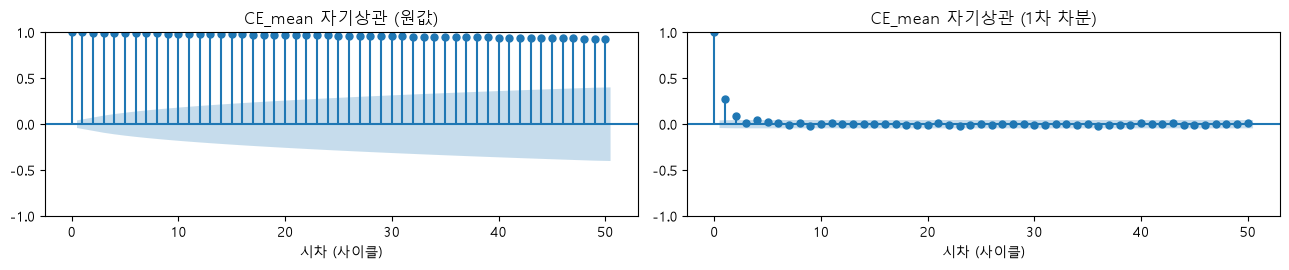

In [6]:
st = stationarity(cyc, ['CE_mean'])
display(st.style.format({"ADF_p": "{:.4f}", "KPSS_p": "{:.3f}"}))
fig, axes = plt.subplots(1, 2, figsize=(13, 2.8))
acf_plot(cyc['CE_mean'], "CE_mean 자기상관 (원값)", ax=axes[0])
acf_plot(cyc['CE_mean'].diff(), "CE_mean 자기상관 (1차 차분)", ax=axes[1])
plt.tight_layout(); plt.show()

## 5. 가설검정 (p-값)

In [7]:
r = kruskal_test(cyc[f], cyc[c])
print(f"Kruskal-Wallis H({r['df']}) = {r['H']:.1f}, p = {r['p']:.3g}, n = {r['n']}")
print("H0 기각" if r["p"] < ALPHA else "H0 유지", f"(α = {ALPHA})")

Kruskal-Wallis H(2) = 1956.4, p = 0, n = 2205
H0 기각 (α = 0.05)


## 6. 사후검정·효과 크기

Kruskal-Wallis는 "어딘가 다르다"만 알려줍니다. **어느 그룹끼리** 다른지는 Dunn 검정으로 짝지어 비교합니다(3쌍이므로 Holm 보정).

In [8]:
display(dunn_test(cyc[f], cyc[c]).style.format({"z": "{:.2f}", "p": "{:.2e}", "p_holm": "{:.2e}"}))
print(f"효과 크기 ε² = {r['eps2']:.3f} → {size_label(r['eps2'])}")

,쌍,z,p,p_holm,유의
0,3 vs 20,-21.94,1.20e-106,1.20e-106,예
1,3 vs 100,-44.23,0.00e+00,0.00e+00,예
2,20 vs 100,-22.23,1.82e-109,3.65e-109,예


효과 크기 ε² = 0.888 → 큼


## 7. 블록 평균으로 재확인

이웃 사이클끼리 비슷하므로(4단계), 연속 50사이클씩 묶어 평균을 낸 뒤 다시 검정합니다. 결론이 같으면 자기상관 때문에 생긴 착시가 아닙니다.

In [9]:
b = block_means(cyc, f, c)
rb = kruskal_test(b[f], b[c])
print(f"블록 {len(b)}개: H({rb['df']}) = {rb['H']:.1f}, p = {rb['p']:.3g}, ε² = {rb['eps2']:.3f}")

블록 47개: H(2) = 40.9, p = 1.32e-09, ε² = 0.889


## 8. 최종 판정

In [10]:
final = pd.DataFrame([dict(가설="H01", 검정="Kruskal-Wallis", 통계량=f"H({r['df']}) = {r['H']:.1f}", p=r["p"],
    효과크기=f"ε² = {r['eps2']:.3f} ({size_label(r['eps2'])})", 블록평균_p=rb["p"],
    판정="H0 기각" if (r["p"] < ALPHA and rb["p"] < ALPHA) else "H0 유지")])
display(final)
save_result("H01", title="냉각기 상태 → 냉각 효율", test="Kruskal-Wallis", stat=final.통계량[0], p=r["p"],
            effect=final.효과크기[0], verdict=final.판정[0])

,가설,검정,통계량,p,효과크기,블록평균_p,판정
0,H01,Kruskal-Wallis,H(2) = 1956.4,0.0,ε² = 0.888 (큼),1.318451e-09,H0 기각


저장: results/H01.json


## 9. 해석과 결정

- 냉각 효율 하나로 냉각기 세 단계가 거의 완벽하게 갈립니다. 효과 크기 ε² ≈ 0.89로 매우 크고, Dunn 세 쌍이 모두 유의하며, 블록 평균으로도 같은 결론입니다.
- **주의:** CE는 다른 센서로 계산한 **가상 센서**라 정답과 매우 가깝습니다. 효과 크기 막대그래프에서 보듯 실제 측정 센서(온도 TS, 압력 PS5·PS6 등)도 효과가 크므로, 발표에서는 이 센서들도 함께 보여 주는 것이 좋습니다.
- **결정:** 냉각기는 "쉬운 문제"입니다. 냉각기 모델은 단순한 LDA로 충분하다는 근거가 됩니다.